Task: For every image, produce a label image with one connected component per part, and
the number of parts. Any pre-processing is allowed (colour spaces, normalisation, denoising,
morphology. . . ) as long as it is justified.

Implement at least N segmentation methodologies of different families (e.g. histogram thresholding, adaptive thresholding, clustering, statistical pixel classification, region growing / watershed, active contours, edge-based. . . ). Two parameter settings of the same algorithm count as one methodology.
• Use the same post-processing for all methods when you compare them, so that the comparison isolates the segmentation step.
• Evaluate on annotated images with, at least, the precision, accuracy and IoU metrics.
• Decide which method is best for this task and explain why, with statistics.

Questions to address: Which colour plane separates the golden screws from the wood? What breaks
a global threshold? How are touching parts handled? Which errors does each method make
(false positives, merges, splits), and are they acceptable for counting?

In [3]:
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

INPUT_DIR = Path("inputs")
VALID_EXTS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

# Filter only supported image extensions
image_paths = sorted([p for p in INPUT_DIR.iterdir() if p.suffix.lower() in VALID_EXTS])

print(f"Total images found: {len(image_paths)}")
if not image_paths:
    raise FileNotFoundError(f"No valid image files found in '{INPUT_DIR.resolve()}'.")

Total images found: 384


In [ ]:
DEV_MODE = True       # Set to False when running tests
DEV_SAMPLE_SIZE = 10   # Quick iteration on just 10 images

if DEV_MODE:
   
    # Pick random spread of  images that covers diferent setups
    dev_stems = {"009","011","018","112","209","377","257","302","199","154"}
    active_paths = [p for p in image_paths if any(p.stem.endswith(s) for s in dev_stems)]
    
    print(f"Running in DEV MODE on {len(active_paths)} images.")
else:
    active_paths = image_paths
    print(f"Running in FULL MODE on all {len(active_paths)} images.")

Running in DEV MODE on 9 images.


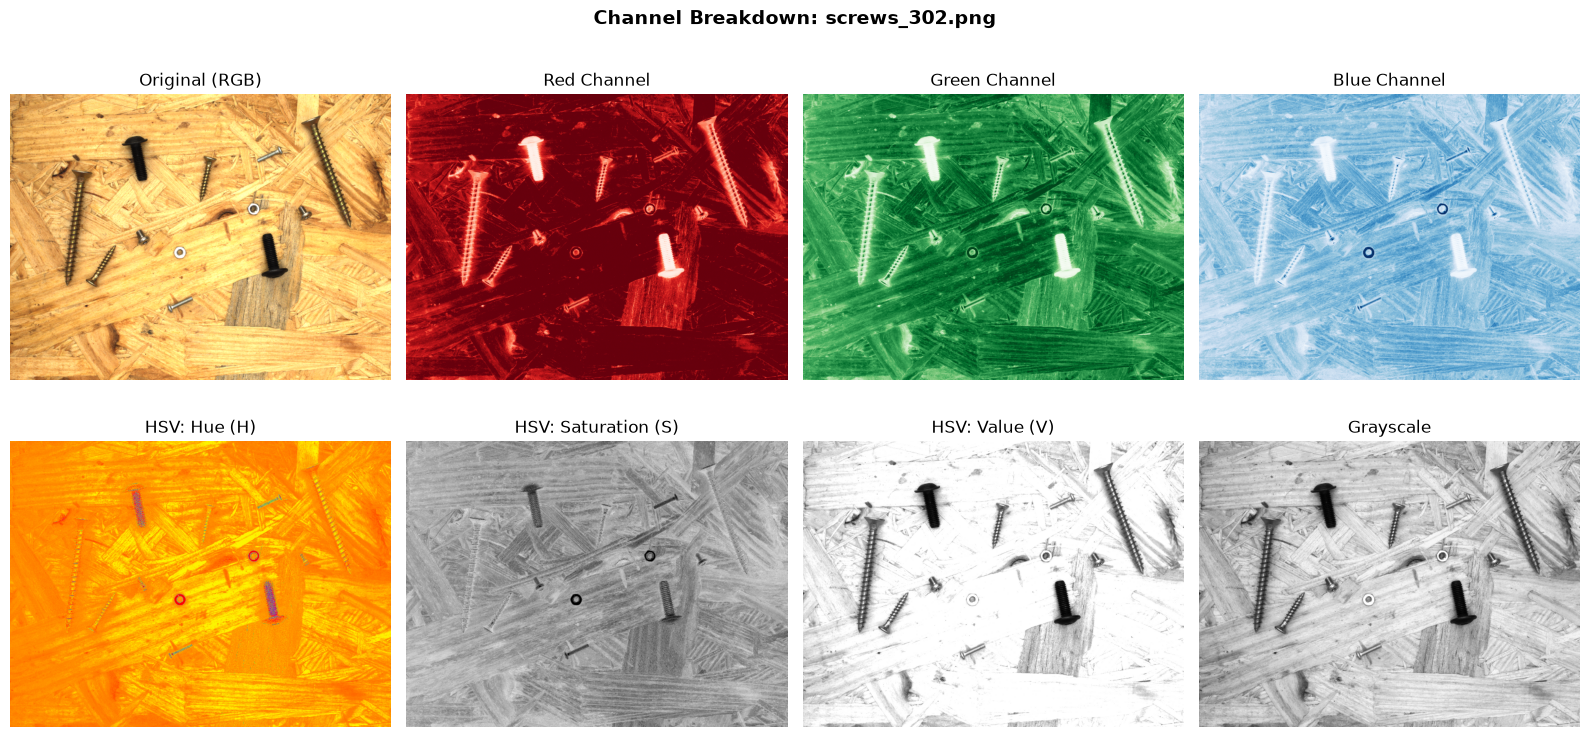

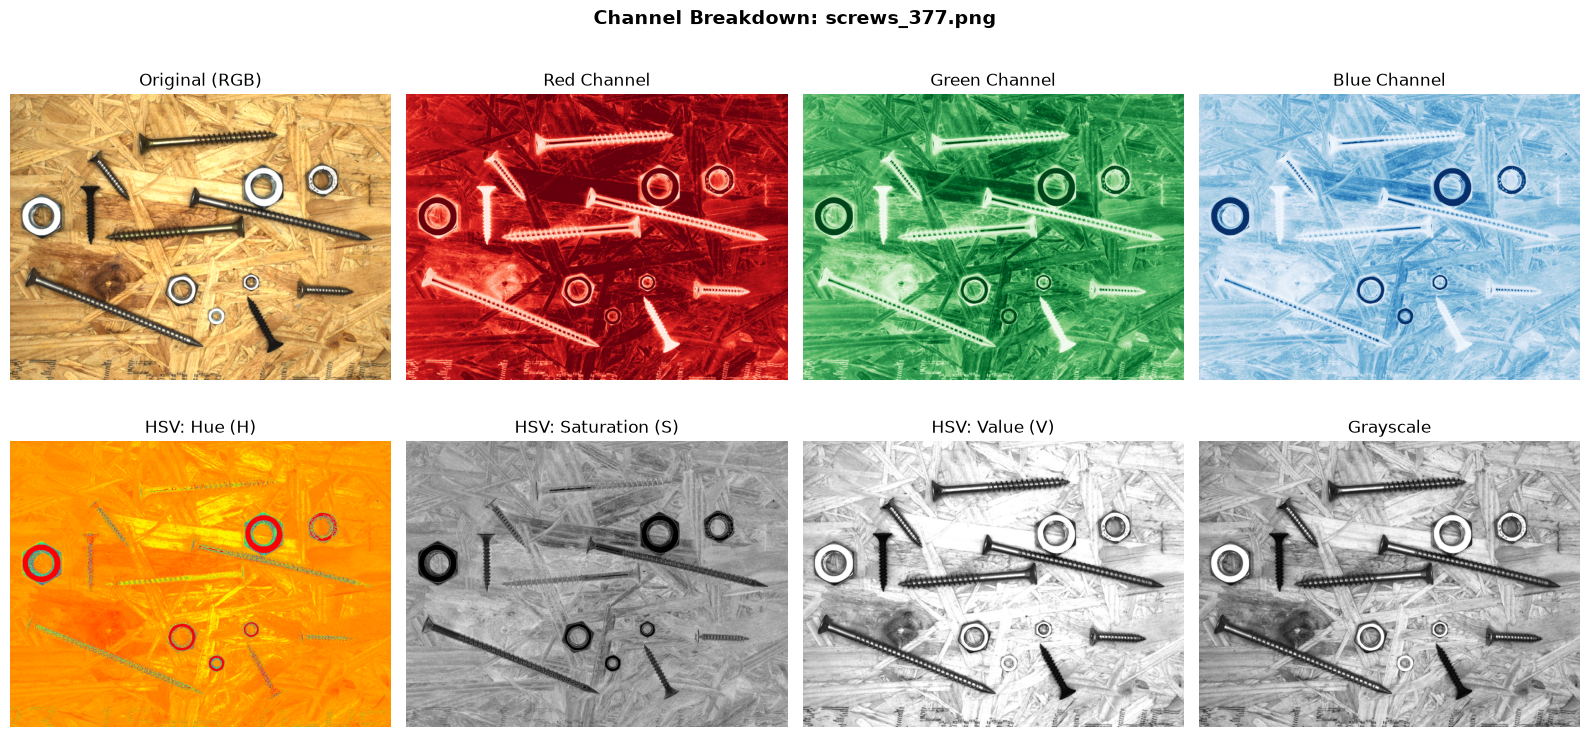

In [31]:
def inspect_image_channels(img_path: Path):
    # cv2.imread loads in BGR
    bgr = cv2.imread(str(img_path))
    if bgr is None:
        print(f"Error loading {img_path}")
        return

    # Color space conversions
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)
    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)

    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    fig.suptitle(f"Channel Breakdown: {img_path.name}", fontsize=14, weight="bold")

    # Row 1: RGB components
    axes[0, 0].imshow(rgb)
    axes[0, 0].set_title("Original (RGB)")
    axes[0, 1].imshow(rgb[:, :, 0], cmap="Reds")
    axes[0, 1].set_title("Red Channel")
    axes[0, 2].imshow(rgb[:, :, 1], cmap="Greens")
    axes[0, 2].set_title("Green Channel")
    axes[0, 3].imshow(rgb[:, :, 2], cmap="Blues")
    axes[0, 3].set_title("Blue Channel")

    # Row 2: HSV & Grayscale components
    axes[1, 0].imshow(hsv[:, :, 0], cmap="hsv")
    axes[1, 0].set_title("HSV: Hue (H)")
    axes[1, 1].imshow(hsv[:, :, 1], cmap="gray")
    axes[1, 1].set_title("HSV: Saturation (S)")
    axes[1, 2].imshow(hsv[:, :, 2], cmap="gray")
    axes[1, 2].set_title("HSV: Value (V)")
    axes[1, 3].imshow(gray, cmap="gray")
    axes[1, 3].set_title("Grayscale")

    for ax in axes.ravel():
        ax.axis("off")

    plt.tight_layout()
    plt.show()

# Run inspection on your dev set
for path in active_paths[-2:]: # last two images have golden screws
    inspect_image_channels(path)

A: From the above output, its clear that the golden screw is part 

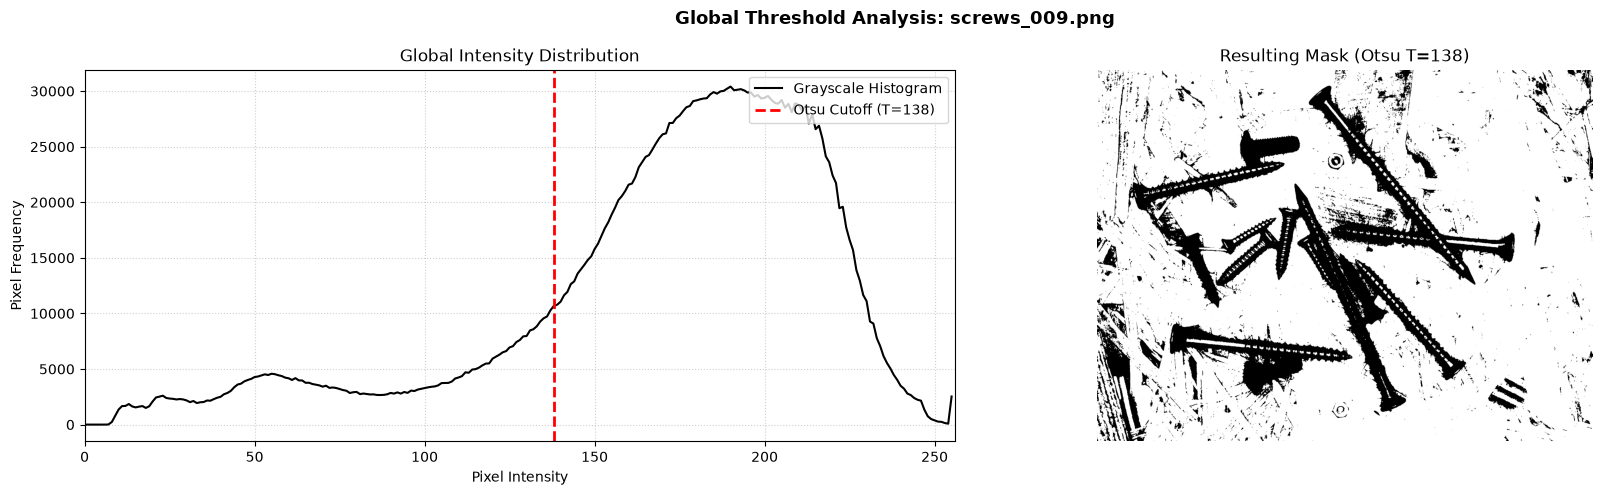

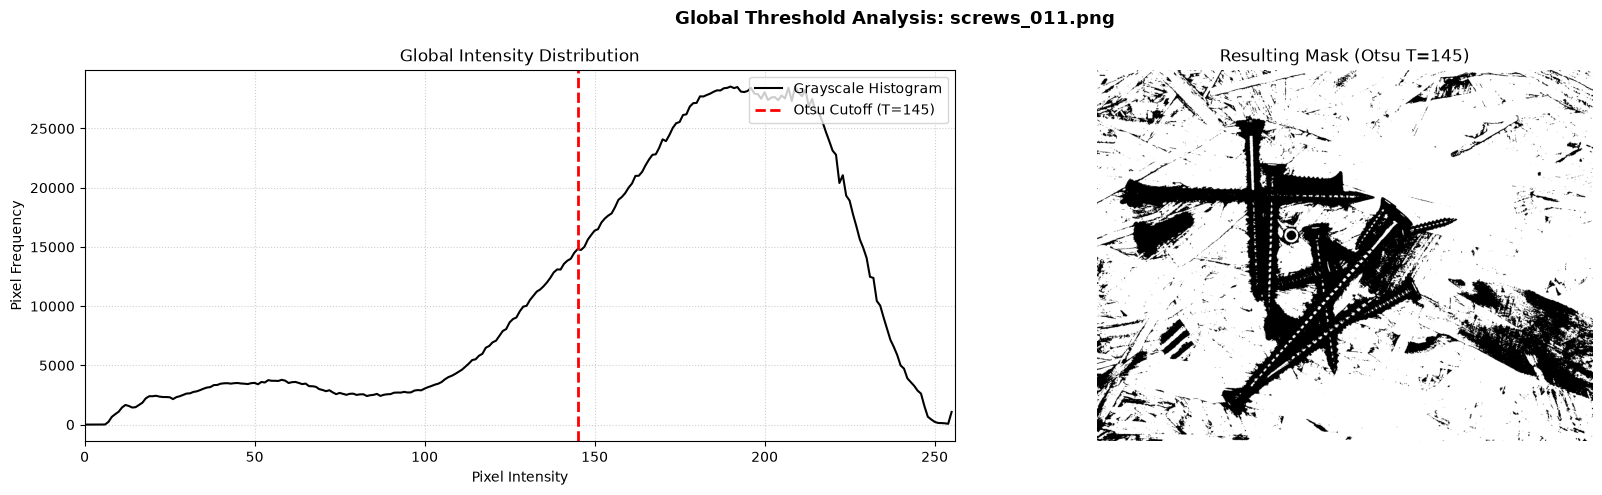

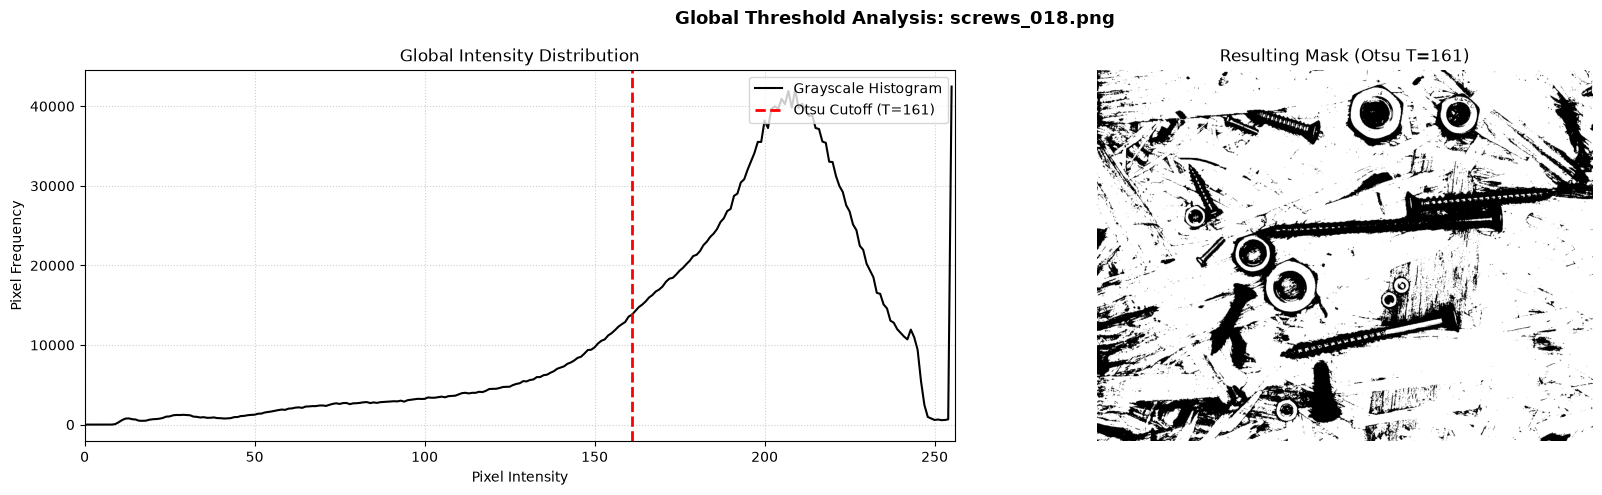

In [34]:
def analyse_global_threshold_breakdown(img_path):
    bgr = cv2.imread(str(img_path))
    if bgr is None:
        return

    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

    # Compute global Otsu threshold
    otsu_val, otsu_mask = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    # Calculate Grayscale and RGB Histograms
    hist_gray = cv2.calcHist([gray], [0], None, [256], [0, 256])

    fig, axes = plt.subplots(1, 2, figsize=(18, 5))
    fig.suptitle(f"Global Threshold Analysis: {img_path.name}", fontsize=13, weight="bold")

    # Grayscale Histogram with the computed Otsu line
    axes[0].plot(hist_gray, color="black", linewidth=1.5, label="Grayscale Histogram")
    axes[0].axvline(otsu_val, color="red", linestyle="--", linewidth=2, label=f"Otsu Cutoff (T={int(otsu_val)})")
    axes[0].set_title("Global Intensity Distribution")
    axes[0].set_xlabel("Pixel Intensity")
    axes[0].set_ylabel("Pixel Frequency")
    axes[0].set_xlim([0, 256])
    axes[0].legend(loc="upper right")
    axes[0].grid(True, linestyle=":", alpha=0.6)

    # Direct visual of global thresholding
    axes[1].imshow(otsu_mask, cmap="gray")
    axes[1].set_title(f"Resulting Mask (Otsu T={int(otsu_val)})")
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()

# Run on sample dev images with gold screws
for path in active_paths[:3]:
    analyse_global_threshold_breakdown(path)

Grayscale with a Global Histogram will not work. The wood background is not uniform and the screws/nuts are different colours. Unimodal. 

Methodologies:
- Option 1: Local Thresholding
- Option 2: Gradient and Marker Controlled Watershed
- Option 3: GMM
- Option 4: K-means